# Weather-normalising Lucknow's PM2.5

**The idea, in plain English**

Winter air in Lucknow is bad, but winter weather is also stagnant (low wind, air trapped close to the ground). So when PM2.5 goes up or down from one year to the next, we can't tell: *did the city pollute more, or was the weather just worse?*

Here is how we separate the two:
1. Train a model to predict PM2.5 **from weather and time of day only**.
2. Ask the model: *"what would PM2.5 have been in each hour if the weather had been typical?"*
3. Whatever change is **left over** after removing weather is not explained by weather. That is what we care about.

**You need:** the clean file from the previous notebook (`lucknow_clean_2020_2025`), in the same folder as this notebook. It works whether it is named `.csv` or `.xls`.

Run the cells top to bottom (Shift + Enter). The normalisation (Step 5) and the lockdown test (Step 6) take about a minute each.

## Step 1: Load the tools and the clean data

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance

file = glob.glob("lucknow_clean_2020_2025.*")[0]
print("Using:", file)

d = pd.read_csv(file, parse_dates=["time"], index_col="time")   # it is a CSV even if the name ends in .xls
d = d.asfreq("h")                                               # one row for every hour
d["year"] = d.index.year
d["month"] = d.index.month
d["hour"] = d.index.hour
print(d.shape)

Using: lucknow_clean_2020_2025.csv
(52602, 17)


## Step 2: Build the model's inputs ("features")
The model sees three kinds of information. **It never sees any pollution reading as an input**, only weather and the calendar, so whatever it learns is purely "what does weather do?"

| Group | Columns | Why |
|---|---|---|
| Weather now | temperature, humidity, wind speed, boundary layer height, pressure, rain | the main drivers |
| Weather memory | the last 24 hours (and 72 hours) of wind, boundary layer height, rain, temperature, humidity | pollution *builds up* when air stays stagnant for a day or more |
| Calendar | hour of day, month, weekday | traffic and heating patterns |
| Trend `t` | years since 1 Jan 2020 | lets the model learn slow changes that are **not** weather (emissions, or changes in the instrument) |

*Boundary layer height* is how tall the layer of air near the ground is. A low value means pollution is squeezed into a thin layer.

In [2]:
# weather memory: averages over the last 24 / 72 hours
d["wind_24h"] = d["wind_speed"].rolling(24, min_periods=12).mean()
d["blh_24h"]  = d["blh_m"].rolling(24, min_periods=12).mean()
d["rain_24h"] = d["rain_mm"].rolling(24, min_periods=12).sum()
d["temp_24h"] = d["temp_c"].rolling(24, min_periods=12).mean()
d["rh_24h"]   = d["humidity_pct"].rolling(24, min_periods=12).mean()
d["wind_72h"] = d["wind_speed"].rolling(72, min_periods=36).mean()
d["rain_72h"] = d["rain_mm"].rolling(72, min_periods=36).sum()
d["pressure_change_24h"] = d["pressure_hpa"].diff(24)

# calendar and trend
d["dow"] = d.index.dayofweek
d["t"] = (d.index - pd.Timestamp("2020-01-01")).total_seconds() / (365.25 * 24 * 3600)

WEATHER = ["temp_c", "humidity_pct", "wind_speed", "blh_m", "pressure_hpa", "rain_mm",
           "wind_24h", "blh_24h", "rain_24h", "temp_24h", "rh_24h", "wind_72h", "rain_72h", "pressure_change_24h"]
CALENDAR = ["hour", "month", "dow"]
FEATURES = WEATHER + CALENDAR + ["t"]

pool = d.dropna(subset=WEATHER).copy()       # every hour that has full weather information
obs = pool.dropna(subset=["pm25"]).copy()    # hours where we also know the real PM2.5
print("Hours used for the model:", len(obs))

Hours used for the model: 50134


## Step 2b: Remove a period where the PM2.5 sensor looks faulty
Notebook 03 compares Lalbagh with a second station (B R Ambedkar University). It found that from about **20 October 2025**, Lalbagh's PM2.5 stopped moving together with its own PM10, and it fell much more than the other station's PM2.5. That looks like an instrument problem, not cleaner air.

We therefore leave out Lalbagh's PM2.5 from that date onward. (The weather data is kept; only the doubtful PM2.5 readings are removed.)

In [3]:
SUSPECT_START = "2025-10-20"        # evidence: notebook 03

before = len(obs)
obs = obs[obs.index < SUSPECT_START].copy()
print("Removed", before - len(obs), "hours from", SUSPECT_START, "to the end of 2025.  Hours left:", len(obs))

Removed 1677 hours from 2025-10-20 to the end of 2025.  Hours left: 48457


## Step 3: How well does weather predict PM2.5?
We use **blocked cross-validation**: cut the data into 2-week blocks, hide some blocks, train on the rest, and predict the hidden ones. Each prediction is made by a model that has never seen that fortnight. (A random split would cheat, because the hour next to a test hour would be in the training data.)

`R²` of 1.0 would be perfect and 0 means no better than guessing the average.

In [4]:
def new_model():
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0)

iso = obs.index.isocalendar()
obs["block"] = iso.year.astype(str) + "-" + (iso.week // 2).astype(str)       # 2-week blocks

cv_pred = pd.Series(np.nan, index=obs.index)
for train_i, test_i in GroupKFold(n_splits=5).split(obs, groups=obs["block"]):
    model = new_model().fit(obs.iloc[train_i][FEATURES], obs.iloc[train_i]["pm25"])
    cv_pred.iloc[test_i] = model.predict(obs.iloc[test_i][FEATURES])

daily = pd.DataFrame({"actual": obs["pm25"], "predicted": cv_pred}).resample("D").mean().dropna()
print("Hourly R2:", round(r2_score(obs["pm25"], cv_pred), 2))
print("Daily  R2:", round(r2_score(daily["actual"], daily["predicted"]), 2))

Hourly R2: 0.64
Daily  R2: 0.78


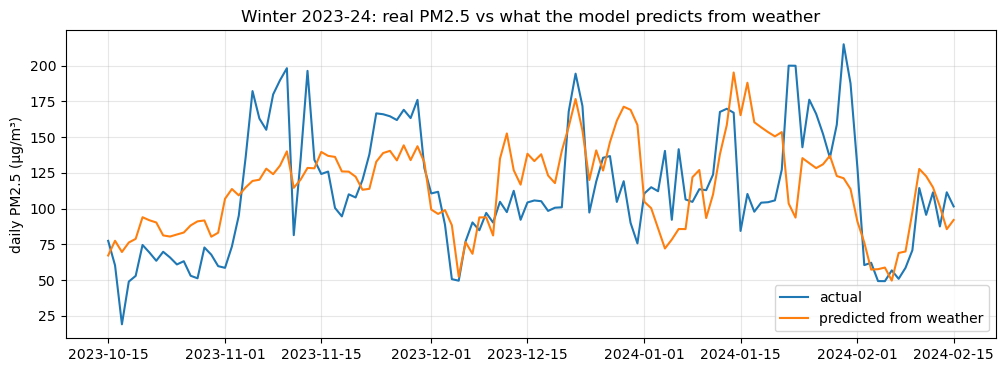

In [5]:
# one winter, actual vs predicted
w = daily["2023-10-15":"2024-02-15"]
plt.figure(figsize=(12, 4))
plt.plot(w.index, w["actual"], label="actual", linewidth=1.5)
plt.plot(w.index, w["predicted"], label="predicted from weather", linewidth=1.5)
plt.ylabel("daily PM2.5 (µg/m³)")
plt.title("Winter 2023-24: real PM2.5 vs what the model predicts from weather")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**What you should see:** hourly R² around **0.64** and daily R² around **0.78**. That is a good result for a model that only knows the weather: it follows the big winter swings (the orange line tracks the blue one).

It cannot be perfect, because it cannot see traffic, burning, industry or construction. The gaps between the two lines are partly those local emissions.

## Step 4: Which weather factors matter most?
**Permutation importance**: shuffle one input at a time and see how much worse the predictions get. A big drop means the model leaned on that input.

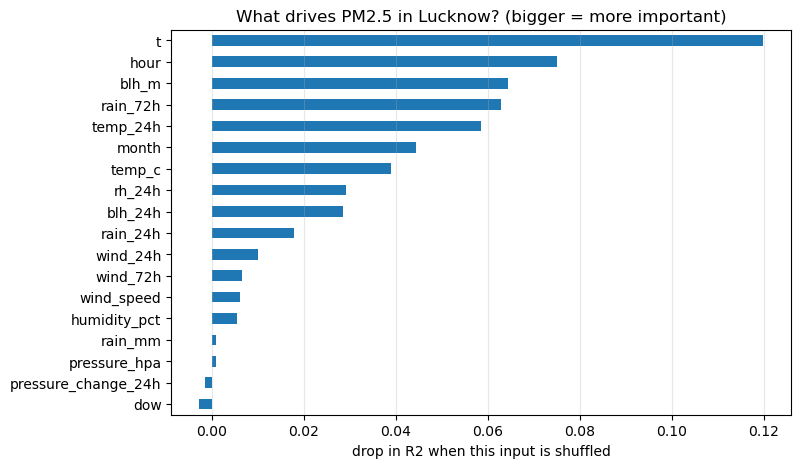

t           0.120
hour        0.075
blh_m       0.064
rain_72h    0.063
temp_24h    0.059
month       0.044
temp_c      0.039
rh_24h      0.029
dtype: float64


In [6]:
# train on 80% of the 2-week blocks, test on the other 20%
train_i, test_i = next(GroupKFold(n_splits=5).split(obs, groups=obs["block"]))
model = new_model().fit(obs.iloc[train_i][FEATURES], obs.iloc[train_i]["pm25"])

imp = permutation_importance(model, obs.iloc[test_i][FEATURES], obs.iloc[test_i]["pm25"],
                             n_repeats=5, random_state=0, scoring="r2")
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

plt.figure(figsize=(8, 5))
imp.plot.barh()
plt.xlabel("drop in R2 when this input is shuffled")
plt.title("What drives PM2.5 in Lucknow? (bigger = more important)")
plt.grid(alpha=0.3, axis="x"); plt.show()
print(imp.sort_values(ascending=False).round(3).head(8))

**What you should see:** `t` (the passage of time) is the longest bar, followed by rain over the last 3 days, hour of day, boundary layer height, and humidity.

How to read it:
- **`t` on top means the biggest driver is not any single weather variable.** PM2.5 level shifted a lot from year to year (for example, high in 2020 and lower since) in ways weather does not explain. Step 7 looks into this.
- **Rain washes the air.** Several dry days make it worse.
- **Weather inputs overlap** (cold nights, low boundary layer and low wind come together), so they share credit. Do not read a small bar as "does not matter".

## Step 5: Weather normalisation
Now the main step. For every hour we ask the model the same question, but **pretend the weather was typical**:

- Keep the real date, hour and trend `t`.
- Replace the weather with the weather from a **random hour in the same month and at the same hour of day**, taken from any of the 6 years. (So a January 2 a.m. gets a typical January 2 a.m., never monsoon weather.)
- Do this 30 times and average the answers.

The result, `pm25_normalised`, is "what PM2.5 would have been under typical weather". The model for this step is trained on **all** the data.

In [7]:
final_model = new_model().fit(obs[FEATURES], obs["pm25"])

rng = np.random.default_rng(0)
N_DRAWS = 30

# for every (month, hour) combination, the list of rows we are allowed to borrow weather from
pool = pool.assign(key=pool["month"] * 24 + pool["hour"])
obs = obs.assign(key=obs["month"] * 24 + obs["hour"])
pool_rows = {k: g[WEATHER].to_numpy() for k, g in pool.groupby("key")}

normalised = np.zeros(len(obs))
for draw in range(N_DRAWS):
    X = obs[FEATURES].copy()
    for k, rows_idx in obs.groupby("key").indices.items():
        borrowed = pool_rows[k][rng.integers(0, len(pool_rows[k]), size=len(rows_idx))]
        X.iloc[rows_idx, [X.columns.get_loc(c) for c in WEATHER]] = borrowed
    normalised += final_model.predict(X)
obs["pm25_normalised"] = normalised / N_DRAWS

print("Done. Average real PM2.5:", round(obs["pm25"].mean(), 1), "| average normalised:", round(obs["pm25_normalised"].mean(), 1))

Done. Average real PM2.5: 81.1 | average normalised: 81.0


**Sanity check:** the two averages should be close. Normalising changes *when* PM2.5 is high or low, not the overall level.

### Raw vs weather-adjusted, by year
Because 2025 now stops on 19 October (Step 2b), we compare **1 January to 19 October of every year**. If we compared full years against a 2025 that is missing its polluted Nov-Dec, 2025 would look unfairly clean.

       raw  weather_adjusted
year                        
2020  78.7              85.3
2021  75.6              77.4
2022  65.8              65.3
2023  67.0              64.3
2024  60.6              57.7
2025  68.4              71.5


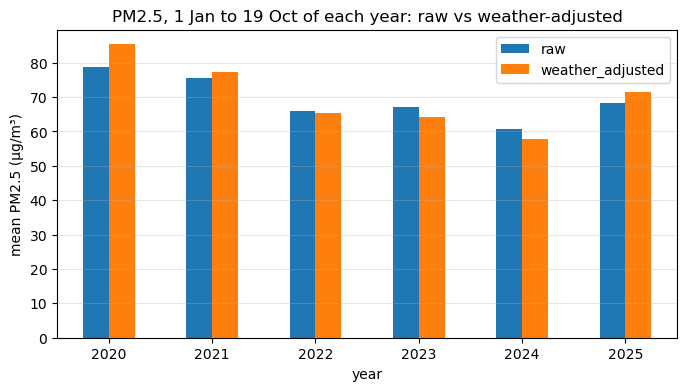

In [8]:
like_for_like = obs[(obs["month"] < 10) | ((obs["month"] == 10) & (obs.index.day < 20))]

yearly = like_for_like.groupby("year")[["pm25", "pm25_normalised"]].mean().round(1)
yearly.columns = ["raw", "weather_adjusted"]
print(yearly)

yearly.plot(kind="bar", figsize=(8, 4))
plt.ylabel("mean PM2.5 (µg/m³)")
plt.title("PM2.5, 1 Jan to 19 Oct of each year: raw vs weather-adjusted")
plt.xticks(rotation=0); plt.grid(alpha=0.3, axis="y"); plt.show()

**What you should see:** in most years the adjusted bar is within about 3 µg/m³ of the raw one. That is normal: over most of a year, good and bad weather average out, so adjusting changes little. The exception is **2020**: raw 79, adjusted 85. Weather in Jan to Oct 2020 was more favourable than usual (together with the lockdown), so under typical weather 2020 would have been dirtier.

Also notice **2025**: for the same dates it is *higher* than 2024 (68 vs 61 raw, 71 vs 58 adjusted). There is no sign of a 2025 improvement.

### The same for winters only (December to February)
Winter is where the weather effect is strongest, so this is where adjustment matters most. We use **complete winters only**: Dec 2020 to Feb 2021, up to Dec 2024 to Feb 2025. The winter of 2025-26 is left out because its PM2.5 is the doubtful period removed in Step 2b.

           raw  weather_adjusted
winter                          
2020-21  183.9             171.7
2021-22   97.3             105.1
2022-23  126.5             117.4
2023-24  106.2             107.6
2024-25  121.3             126.2


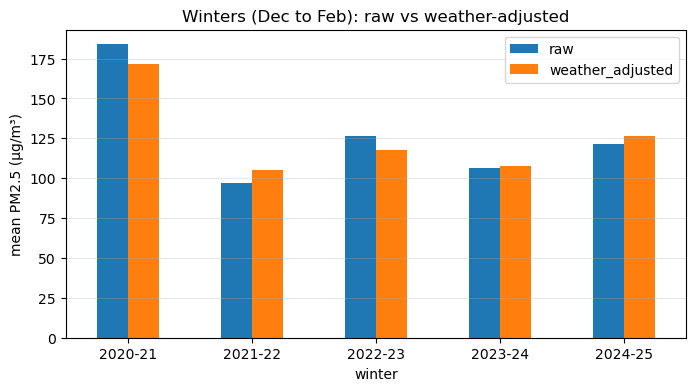

In [9]:
winter = obs[obs["month"].isin([12, 1, 2])].copy()
winter["winter"] = np.where(winter["month"] == 12, winter["year"], winter["year"] - 1)   # Dec 2020 + Jan, Feb 2021 = winter "2020"
winter = winter[(winter["winter"] >= 2020) & (winter["winter"] <= 2024)]                  # complete winters only
winter["winter"] = winter["winter"].astype(str) + "-" + (winter["winter"] + 1).astype(str).str[-2:]

wy = winter.groupby("winter")[["pm25", "pm25_normalised"]].mean().round(1)
wy.columns = ["raw", "weather_adjusted"]
print(wy)

wy.plot(kind="bar", figsize=(8, 4))
plt.ylabel("mean PM2.5 (µg/m³)")
plt.title("Winters (Dec to Feb): raw vs weather-adjusted")
plt.xticks(rotation=0); plt.grid(alpha=0.3, axis="y"); plt.show()

**What you should see:** in winter the adjustment is bigger, up to about 12 µg/m³. Winter 2020-21 was **184 raw but 171 weather-adjusted**: part of that winter's smog was just bad weather. Winter 2021-22 goes the other way (97 raw, 104 adjusted): the weather was helping that year.

After the high winter of 2020-21, the weather-adjusted values stay between roughly **104 and 126 µg/m³** with no clear downward trend. In plain words: once weather is accounted for, these data do **not** show a steady improvement in Lucknow's winter air.

### Month by month
The weather-adjusted line should be **smoother**: the jumps that came from weather are removed.

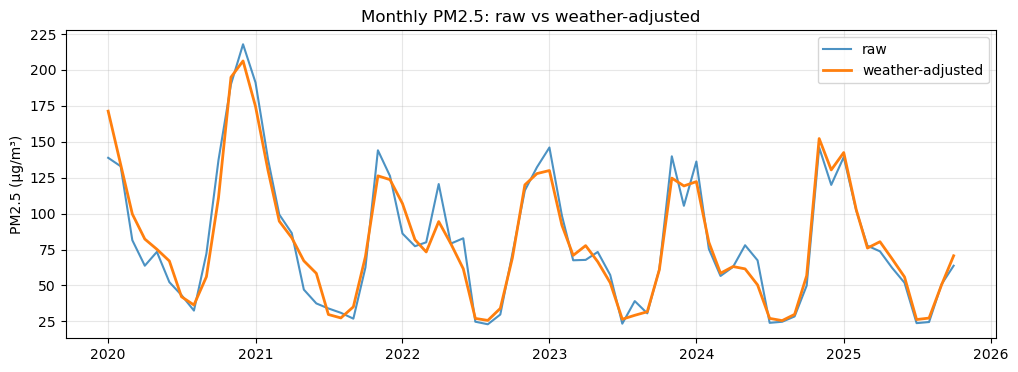

In [10]:
monthly = obs[["pm25", "pm25_normalised"]].resample("MS").mean()
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly["pm25"], label="raw", alpha=0.8)
plt.plot(monthly.index, monthly["pm25_normalised"], label="weather-adjusted", linewidth=2)
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Monthly PM2.5: raw vs weather-adjusted")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**What you should see:** the orange line follows the same yearly cycle but with some of the sharp spikes shaved off.

## Step 6: Did the 2020 lockdown cut pollution?
Idea: **hide** the lockdown period (25 Mar to 31 May 2020), train the model on everything else, and predict what PM2.5 *would* have been using the **real weather** of those weeks. Compare with what was measured.

To know whether a gap is meaningful, we repeat the exact same test for the same calendar window in **every other year** (hiding that year's window instead). Those years had no lockdown, so their gaps show how wrong the method normally is.

In [11]:
def window(year):
    return (obs.index >= f"{year}-03-25") & (obs.index < f"{year}-06-01")

lockdown = window(2020)
rows = []
for y in range(2020, 2026):
    hide = window(y)
    train = obs[~hide & ~lockdown]            # never train on the lockdown weeks
    m = new_model().fit(train[FEATURES], train["pm25"])
    test = obs[hide]
    actual, predicted = test["pm25"].mean(), m.predict(test[FEATURES]).mean()
    rows.append({"year": y, "measured": round(actual, 1), "expected": round(predicted, 1),
                 "change_pct": round((actual / predicted - 1) * 100)})

lock = pd.DataFrame(rows).set_index("year")
print(lock)

      measured  expected  change_pct
year                                
2020      67.4     108.6         -38
2021      67.4      80.3         -16
2022      98.1      80.8          21
2023      69.5      66.9           4
2024      70.4      74.2          -5
2025      68.8      67.1           3


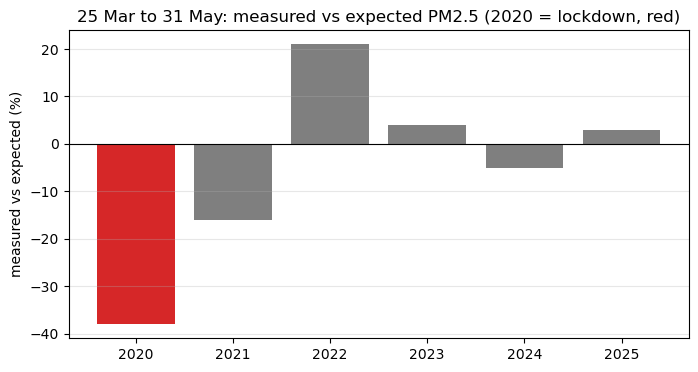

In [12]:
colors = ["tab:red" if y == 2020 else "tab:gray" for y in lock.index]
plt.figure(figsize=(8, 4))
plt.bar(lock.index.astype(str), lock["change_pct"], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("measured vs expected (%)")
plt.title("25 Mar to 31 May: measured vs expected PM2.5 (2020 = lockdown, red)")
plt.grid(alpha=0.3, axis="y"); plt.show()

**What you should see:** 2020 is about **36% below** what the weather predicted. That is the biggest gap of the six years.

But be careful how you describe it:
- The method is not exact. In years with no lockdown the gap ranges from about **-16% (2021) to +22% (2022)**, so the normal error is roughly plus or minus 20%.
- 2021 is also well below expectation. Spring 2021 had COVID restrictions during the second wave (the cause is not checked here), so it may not be a clean "no-lockdown" comparison.
- A fair summary: *"PM2.5 was about 36% below the weather-based expectation during the 2020 lockdown, the largest shortfall of six years, though the method's uncertainty is around 20%."*

## Step 7: A warning sign to check before you believe any trend
Weather cannot explain everything. If PM2.5 falls but the other measurements do not, the cause may be the **instrument**, not the air. A simple test: **PM2.5 is part of PM10**, so the ratio PM2.5 / PM10 should be fairly stable from year to year.

In [13]:
nd = d[d["month"].isin([11, 12])].copy()
nd["ratio"] = nd["pm25"] / nd["pm10"]
check = nd.groupby("year").agg(pm25=("pm25", "mean"), pm10=("pm10", "mean"),
                               no2=("no2", "mean"), ratio=("ratio", "median"),
                               blh=("blh_m", "mean"), wind=("wind_speed", "mean")).round(2)
print("Nov + Dec averages by year:")
print(check)

Nov + Dec averages by year:
        pm25    pm10    no2  ratio     blh  wind
year                                            
2020  204.24  330.41  77.87   0.63  313.12  2.24
2021  134.95  267.37  61.95   0.52  307.13  1.93
2022  124.31  256.50  54.50   0.50  295.92  2.22
2023  122.60  240.82  44.63   0.51  305.15  1.90
2024  132.75  288.90  32.24   0.46  339.23  1.99
2025   86.18  261.63  32.63   0.34  299.83  2.06


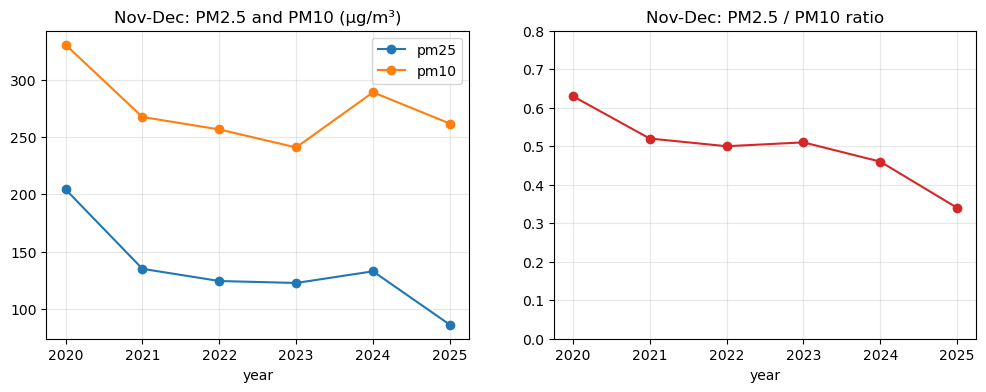

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
check[["pm25", "pm10"]].plot(ax=ax[0], marker="o")
ax[0].set_title("Nov-Dec: PM2.5 and PM10 (µg/m³)"); ax[0].grid(alpha=0.3)
check["ratio"].plot(ax=ax[1], marker="o", color="tab:red")
ax[1].set_title("Nov-Dec: PM2.5 / PM10 ratio"); ax[1].set_ylim(0, 0.8); ax[1].grid(alpha=0.3)
plt.show()

**What you should see:** from 2024 to 2025 in Nov and Dec:

| | 2024 | 2025 | change |
|---|---|---|---|
| PM2.5 | 133 | 86 | **-35%** |
| PM10 | 289 | 262 | -9% |
| NO2 | 32 | 33 | no change |
| Boundary layer height | 339 m | 300 m | lower, so weather was *less* favourable |
| Wind speed | 2.0 m/s | 2.1 m/s | no change |
| PM2.5 / PM10 ratio | 0.46 | **0.34** | falls |

The ratio has also been sliding since 2020 (0.63, 0.52, 0.50, 0.51, 0.46, 0.34).

**What this means:** fine particles dropped sharply while coarse particles, NO2 and the weather did not. That pattern is what you would see if the **PM2.5 instrument changed or drifted**, although a real change in fine-particle sources cannot be ruled out.

**What notebook 03 found when we checked against a second station (B R Ambedkar University):**
- In Nov-Dec 2025, PM2.5 fell about **34%** at Lalbagh but only about **14%** at the other station. PM10 fell about 8 to 9% at both, so coarse particles agree.
- Lalbagh's PM2.5 normally runs at about 0.46 to 0.50 times its PM10 and moves up and down with it (correlation 0.8 to 0.9). In Nov-Dec 2025 that fell to **0.32**, with a correlation of only **0.33**. The other station stayed normal.
- Week by week, the change starts around **20 October 2025**, lasts through winter, and Lalbagh is back to normal by about March 2026.

This is strong circumstantial evidence of an instrument problem at Lalbagh, not proof. (The other station's own 2025 PM2.5 also looks odd in places, so it is an imperfect reference.) The safest reading: **Lalbagh's PM2.5 from 20 October 2025 is not reliable**, and that is why Step 2b removes it.

**So do not claim "Lucknow's air improved in 2025".** The big drop is mostly a data problem. Catching it, checking it against a second station, and removing the doubtful period is exactly the kind of care that makes a project credible to a hiring manager.

## Step 8: Save your results

In [15]:
out = obs[["pm25", "pm25_normalised"]].copy()
out["year"] = out.index.year
out.to_csv("lucknow_weather_normalised.csv")
lock.to_csv("lucknow_lockdown_check.csv")
print("Saved: lucknow_weather_normalised.csv and lucknow_lockdown_check.csv")

Saved: lucknow_weather_normalised.csv and lucknow_lockdown_check.csv


## Step 9: Tables ready for Power BI
Power BI is easier to use with small, tidy tables than with 48,000 hourly rows. This step writes five of them. Each is a plain CSV (load it in Power BI with *Get data > Text/CSV*).

| File | One row per | Use it for |
|---|---|---|
| `dash_daily.csv` | day | the calendar heatmap and daily trend |
| `dash_monthly.csv` | month | raw vs weather-adjusted over time |
| `dash_yearly.csv` | year (1 Jan to 19 Oct) | yearly comparison |
| `dash_winters.csv` | winter (Dec to Feb) | the winter comparison |
| `dash_hourly_profile.csv` | season and hour of day | the "when in the day" chart |

The `pm25_band` column uses the official CPCB PM2.5 bands for a 24-hour average (Good up to 30, Satisfactory 31 to 60, Moderate 61 to 90, Poor 91 to 120, Very poor 121 to 250, Severe above 250), so the heatmap colours mean something.

In [16]:
# --- daily ---
daily_tbl = obs.groupby(obs.index.date).agg(
    pm25_raw=("pm25", "mean"), pm25_adjusted=("pm25_normalised", "mean"), hours=("pm25", "size"),
    temp_c=("temp_c", "mean"), wind_speed=("wind_speed", "mean"), blh_m=("blh_m", "mean"), rain_mm=("rain_mm", "sum"))
daily_tbl.index = pd.to_datetime(daily_tbl.index)
daily_tbl.index.name = "date"
daily_tbl = daily_tbl[daily_tbl["hours"] >= 18]                       # keep days with at least 18 valid hours
daily_tbl["pm25_band"] = pd.cut(daily_tbl["pm25_raw"], [0, 30, 60, 90, 120, 250, np.inf],
                                labels=["Good", "Satisfactory", "Moderate", "Poor", "Very poor", "Severe"])
daily_tbl.round(2).to_csv("dash_daily.csv")

# --- monthly, yearly, winters ---
monthly_tbl = monthly.rename(columns={"pm25": "raw", "pm25_normalised": "weather_adjusted"}).round(1)
monthly_tbl.index.name = "month"
monthly_tbl.to_csv("dash_monthly.csv")
yearly.to_csv("dash_yearly.csv")
wy.to_csv("dash_winters.csv")

# --- hour-of-day profile by season ---
season_of = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
             6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}
profile = (obs.assign(season=obs["month"].map(season_of))
              .groupby(["season", "hour"])["pm25"].mean().round(1).reset_index())
profile.to_csv("dash_hourly_profile.csv", index=False)

print("Saved: dash_daily.csv (%d days), dash_monthly.csv, dash_yearly.csv, dash_winters.csv, dash_hourly_profile.csv" % len(daily_tbl))
daily_tbl.head()

Saved: dash_daily.csv (2034 days), dash_monthly.csv, dash_yearly.csv, dash_winters.csv, dash_hourly_profile.csv


,pm25_raw,pm25_adjusted,hours,temp_c,wind_speed,blh_m,rain_mm,pm25_band
date,,,,,,,,
2020-01-03,77.343750,165.246763,24,15.525401,2.382244,279.460816,13.524532,Moderate
2020-01-04,99.607500,164.644916,24,14.520369,1.687479,218.354521,0.244141,Poor
2020-01-05,100.780526,167.197049,19,13.545781,3.096113,384.846222,0.020027,Poor
2020-01-06,126.195652,163.049432,23,14.726427,2.866447,284.120942,0.000000,Very poor
2020-01-07,117.064167,163.234687,24,15.483494,1.587058,232.300941,0.000000,Poor
